# Transformer Scaling Study
Test Accuracy vs. Data Size for RT (Reflection-Based) and VT (Validation-Based) models.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

## Data

In [2]:
data_sizes   = [99_000, 396_000, 792_000, 990_000, 1_480_000, 2_170_000, 5_140_000]
x_labels     = ['99K', '396K', '792K', '990K', '1.48M', '2.17M', '5.14M']

rt_top1 = [57.45, 80.37, 86.59, 89.77, 91.86, 93.71, 94.35]
rt_top3 = [78.75, 94.18, 97.05, 97.92, 98.78, 99.19, 99.50]
rt_top5 = [86.79, 97.11, 98.62, 98.99, 99.50, 99.68, 99.86]

vt_top1 = [21.70, 30.85, 37.18, 42.48, 52.32, 60.93, 71.83]
vt_top3 = [38.06, 49.43, 60.57, 65.30, 77.66, 85.11, 91.67]
vt_top5 = [46.75, 59.61, 71.53, 76.26, 86.54, 91.93, 95.95]

## Plot

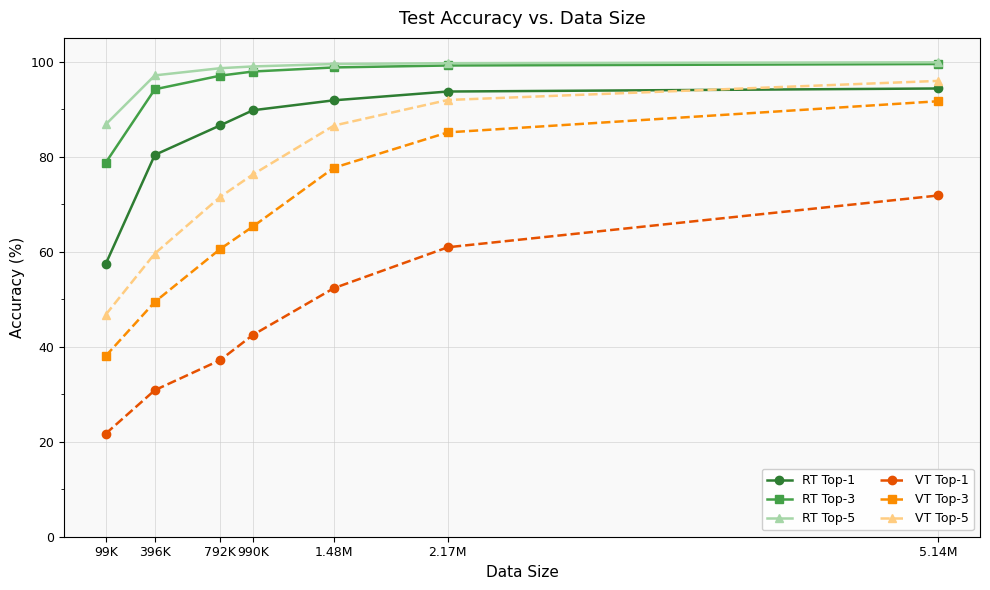

Saved → scaling_study.png


In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

# ── colours: green family for RT, orange family for VT ──
rt_colors = ['#2e7d32', '#43a047', '#a5d6a7']   # dark → light green
vt_colors = ['#e65100', '#fb8c00', '#ffcc80']   # dark → light orange

marker_kw = dict(linewidth=1.8, markersize=6, markeredgewidth=1.0)

ax.plot(data_sizes, rt_top1, color=rt_colors[0], marker='o', label='RT Top-1', **marker_kw)
ax.plot(data_sizes, rt_top3, color=rt_colors[1], marker='s', label='RT Top-3', **marker_kw)
ax.plot(data_sizes, rt_top5, color=rt_colors[2], marker='^', label='RT Top-5', **marker_kw)

ax.plot(data_sizes, vt_top1, color=vt_colors[0], marker='o', linestyle='--', label='VT Top-1', **marker_kw)
ax.plot(data_sizes, vt_top3, color=vt_colors[1], marker='s', linestyle='--', label='VT Top-3', **marker_kw)
ax.plot(data_sizes, vt_top5, color=vt_colors[2], marker='^', linestyle='--', label='VT Top-5', **marker_kw)

# ── axes ──
ax.set_title('Test Accuracy vs. Data Size', fontsize=13, pad=10)
ax.set_xlabel('Data Size', fontsize=11)
ax.set_ylabel('Accuracy (%)', fontsize=11)

ax.set_xticks(data_sizes)
ax.set_xticklabels(x_labels, fontsize=9)
ax.tick_params(axis='y', labelsize=9)
ax.set_ylim(0, 105)
ax.yaxis.set_major_locator(ticker.MultipleLocator(20))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(10))

# ── grid matching reference style ──
ax.grid(True, which='major', linestyle='-', linewidth=0.5, color='#cccccc', alpha=0.8)
ax.set_facecolor('#f9f9f9')
fig.patch.set_facecolor('white')

# ── legend ──
ax.legend(loc='lower right', fontsize=9, framealpha=0.95,
          edgecolor='#cccccc', ncol=2)

plt.tight_layout()
plt.savefig('scaling_study.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → scaling_study.png')